<a href="https://colab.research.google.com/github/adytriaby/PCVK_Ganjil2026/blob/main/week9_PCDVK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 — Morfologi Citra
### Pengolahan Citra dan Visi Komputer

**Nama:** Adytria Bayu Ramadani
**NIM:** 254107023004
**Kelas:** TI 3E


## 0. Setup

Import library, pengaturan tampilan, dan penanda apakah notebook berjalan di Colab.
`google.colab` hanya tersedia di Colab sehingga dibungkus `try/except` agar notebook tetap bisa diuji secara lokal.

In [13]:
import os
import re
import sys
import time
import subprocess
import warnings

import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage import filters, morphology
from skimage.morphology import skeletonize, thin

try:
    from google.colab import files
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

try:
    import pytesseract
    OCR_TERSEDIA = True
except Exception:
    OCR_TERSEDIA = False

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["image.cmap"] = "gray"
np.random.seed(42)

print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)
print("Colab  :", IN_COLAB)
print("OCR    :", OCR_TERSEDIA)

OpenCV : 5.0.0
NumPy  : 2.1.3
Colab  : True
OCR    : False


### Mount Google Drive dan upload citra



In [14]:
FOLDER_DRIVE = "/content/drive/MyDrive/PCVK/Images"
DAFTAR_CITRA = [
    "plat nomer.jpg",
    "lily.jpg",
    "kitten01.jpg",
    "j.png",
    "ktp1_fulan.jpg",
    "ktp2_fulani.jpg",
]

PENGGANTI = {
    "plat nomer.jpg": "ktp1_fulan.jpg",
    "lily.jpg": "djawatan.jpg",
    "kitten01.jpg": "djawatan.jpg",
    "j.png": "ktp2_fulani.jpg",
}

if IN_COLAB:
    try:
        drive.mount("/content/drive")
    except Exception as e:
        print("Drive tidak terpasang:", e)
else:
    print("Mode lokal: citra dibaca dari folder kerja.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
if IN_COLAB:
    belum = [
        nama for nama in DAFTAR_CITRA
        if not os.path.exists(nama) and not os.path.exists(os.path.join(FOLDER_DRIVE, nama))
    ]
    if belum:
        print("Citra berikut belum ditemukan. Upload sekarang (boleh lebih dari satu file):")
        for nama in belum:
            print(" -", nama)
        unggah = files.upload()
        print("Terunggah:", list(unggah.keys()))
    else:
        print("Semua citra sudah tersedia.")
else:
    print("Upload dilewati (mode lokal).")

Citra berikut belum ditemukan. Upload sekarang (boleh lebih dari satu file):
 - plat nomer.jpg
 - lily.jpg
 - kitten01.jpg
 - j.png


Saving j.jpeg to j (2).jpeg
Saving kitten01.jpeg to kitten01 (2).jpeg
Saving lily.jpeg to lily.jpeg
Saving plat nomer.png to plat nomer (2).png
Terunggah: ['j (2).jpeg', 'kitten01 (2).jpeg', 'lily.jpeg', 'plat nomer (2).png']


In [16]:
def _kunci(nama):
    """Normalkan nama file: huruf kecil, tanpa spasi/underscore/tanda baca."""
    return re.sub(r"[^a-z0-9]", "", nama.lower())


def cari_citra(nama):
    """Cari citra di folder kerja, folder Drive, dan /content (termasuk variasi nama)."""
    kandidat = [nama, os.path.join(FOLDER_DRIVE, nama), os.path.join("/content", nama)]
    for jalur in kandidat:
        if os.path.exists(jalur):
            return jalur

    kunci_penuh = _kunci(nama)
    kunci_stem = _kunci(os.path.splitext(nama)[0])
    for folder in [".", FOLDER_DRIVE, "/content"]:
        if not os.path.isdir(folder):
            continue
        for berkas in sorted(os.listdir(folder)):
            if _kunci(berkas) == kunci_penuh or _kunci(os.path.splitext(berkas)[0]) == kunci_stem:
                return os.path.join(folder, berkas)
    return None


def muat(nama, pengganti=None, warna=False, lebar_maks=700):
    """Muat citra; jika tidak ada, pakai citra pengganti dan beri peringatan."""
    jalur = cari_citra(nama)
    if jalur is None and pengganti is not None:
        jalur = cari_citra(pengganti)
        if jalur is not None:
            print(f"[info] '{nama}' tidak ditemukan -> memakai '{pengganti}'")
    if jalur is None:
        raise FileNotFoundError(
            f"Citra '{nama}' tidak ditemukan. Upload ke /content atau simpan di {FOLDER_DRIVE}."
        )

    mode = cv2.IMREAD_COLOR if warna else cv2.IMREAD_GRAYSCALE
    img = cv2.imread(jalur, mode)
    if img is None:
        raise ValueError(f"'{jalur}' gagal dibaca sebagai citra.")

    if lebar_maks and img.shape[1] > lebar_maks:
        skala = lebar_maks / img.shape[1]
        img = cv2.resize(img, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)

    print(f"{nama:<20} <- {jalur:<50} shape={img.shape}")
    return img

In [17]:
def tampilkan(daftar_citra, judul=None, cmap="gray", ncols=None, skala=4.2):
    """Tampilkan satu atau beberapa citra dalam grid."""
    if not isinstance(daftar_citra, (list, tuple)):
        daftar_citra = [daftar_citra]
    n = len(daftar_citra)
    judul = judul or [""] * n
    ncols = ncols or n
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(skala * ncols, skala * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, im, t in zip(axes, daftar_citra, judul):
        ax.imshow(im, cmap=cmap if np.ndim(im) == 2 else None)
        ax.set_title(t, fontsize=10)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(fig)


def binarisasi(img, metode="otsu", blok=31, c=10, nilai=127, batas_atas=225):
    """Binarisasi: 'otsu' | 'adaptif' (Gaussian) | 'manual' (threshold tetap seperti modul)."""
    if metode == "otsu":
        _, hasil = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    elif metode == "adaptif":
        blok = blok if blok % 2 == 1 else blok + 1
        hasil = cv2.adaptiveThreshold(
            img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, blok, c
        )
    elif metode == "manual":
        _, hasil = cv2.threshold(img, nilai, batas_atas, cv2.THRESH_BINARY)
    else:
        raise ValueError(f"metode tidak dikenal: {metode}")
    return hasil


def se_persegi(w):
    return np.ones((w, w), dtype=np.uint8)


def se_persegi_panjang(tinggi, lebar):
    return np.ones((tinggi, lebar), dtype=np.uint8)


def se_cross(w):
    se = np.zeros((w, w), dtype=np.uint8)
    tengah = w // 2
    se[tengah, :] = 1
    se[:, tengah] = 1
    return se


def se_garis_vertikal(k):
    return np.ones((k, 1), dtype=np.uint8)

In [18]:
print(f"{'Nama':<20}{'Status':<12}Jalur")
print("-" * 78)
for nama in DAFTAR_CITRA:
    jalur = cari_citra(nama)
    if jalur:
        print(f"{nama:<20}{'OK':<12}{jalur}")
    else:
        print(f"{nama:<20}{'TIDAK ADA':<12}-> pengganti: {PENGGANTI.get(nama, '-')}")

Nama                Status      Jalur
------------------------------------------------------------------------------
plat nomer.jpg      OK          ./plat nomer.png
lily.jpg            OK          ./lily.jpeg
kitten01.jpg        OK          ./kitten01.jpeg
j.png               OK          ./j.jpeg
ktp1_fulan.jpg      OK          ktp1_fulan.jpg
ktp2_fulani.jpg     OK          ktp2_fulani.jpg


---

# D. Praktikum Morfologi

## D.1 Dilasi manual (tanpa library morfologi)

Dilasi memperbesar objek: piksel referensi menjadi 255 jika **minimal satu** piksel di dalam
*structuring element* (SE) bernilai 1.

Dua implementasi dibuat:

- `dilasi_manual()` — loop literal seperti modul (mudah dibaca, lambat).
- `dilasi_cepat()` — loop hanya pada elemen SE yang bernilai 1 (jauh lebih cepat, hasil identik).

Border tidak diproses sehingga tetap 0, sama seperti kode modul.

In [19]:
def dilasi_manual(F, se):
    """Dilasi manual (loop literal modul)."""
    p, q = F.shape
    kh, kw = se.shape
    a, b = kh // 2, kw // 2

    hasil = np.zeros((p, q), dtype=np.uint8)
    for i in range(a, p - a):
        for j in range(b, q - b):
            temp = F[i - a:i + a + 1, j - b:j + b + 1]
            hasil[i, j] = np.max(temp * se)
    return hasil


def dilasi_cepat(F, se):
    """Dilasi vectorized: loop hanya pada elemen SE yang bernilai 1."""
    p, q = F.shape
    kh, kw = se.shape
    a, b = kh // 2, kw // 2

    pad = np.pad(F, ((a, kh - 1 - a), (b, kw - 1 - b)), mode="constant")
    hasil = np.zeros((p, q), dtype=np.uint8)
    for u in range(kh):
        for v in range(kw):
            if se[u, v]:
                hasil = np.maximum(hasil, pad[u:u + p, v:v + q])

    hasil[:a, :] = 0
    hasil[p - a:, :] = 0
    hasil[:, :b] = 0
    hasil[:, q - b:] = 0
    return hasil

In [ ]:
img_d = muat("plat nomer.jpg", PENGGANTI["plat nomer.jpg"])
_, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)

w = 5
t0 = time.time()
imgD_manual = dilasi_manual(thresh, se_persegi(w))
t_manual = time.time() - t0

t0 = time.time()
imgD_cepat = dilasi_cepat(thresh, se_persegi(w))
t_cepat = time.time() - t0

print(f"SE persegi {w}x{w}")
print(f"loop literal : {t_manual:6.2f} s")
print(f"vectorized   : {t_cepat:6.3f} s")
print("hasil identik:", np.array_equal(imgD_manual, imgD_cepat))
print("piksel putih :", cv2.countNonZero(thresh), "->", cv2.countNonZero(imgD_manual))

tampilkan(
    [img_d, thresh, imgD_manual],
    ["Citra awal", "Biner (125, 200)", f"Dilasi manual SE {w}x{w}"],
    ncols=3, skala=5,
)

plat nomer.jpg       <- ./plat nomer.png                                   shape=(220, 667)


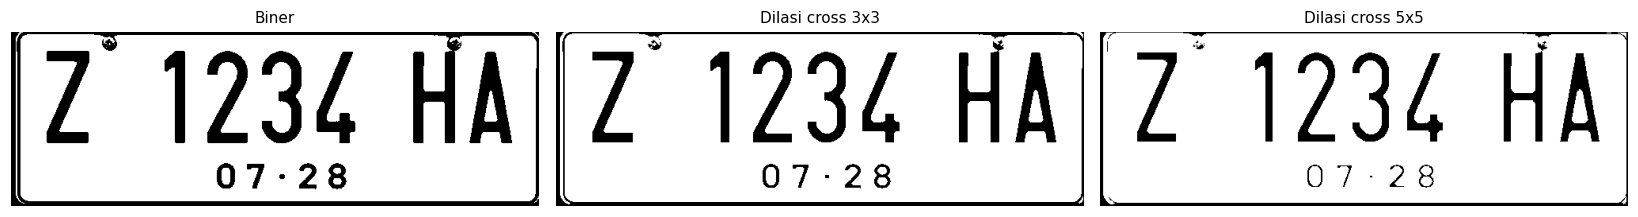

In [21]:
hasil_cross = {w: dilasi_cepat(thresh, se_cross(w)) for w in (3, 5)}
tampilkan(
    [thresh] + list(hasil_cross.values()),
    ["Biner", "Dilasi cross 3x3", "Dilasi cross 5x5"],
    ncols=3, skala=5,
)

## D.2 Dilasi dengan library OpenCV

SE cross 3x3 dibentuk dengan `cv2.getStructuringElement`, lalu hasilnya dibandingkan dengan implementasi manual.

SE cross 3x3 dari OpenCV:
 [[0 1 0]
 [1 1 1]
 [0 1 0]]
piksel berbeda: 34 (0.023% dari total piksel)


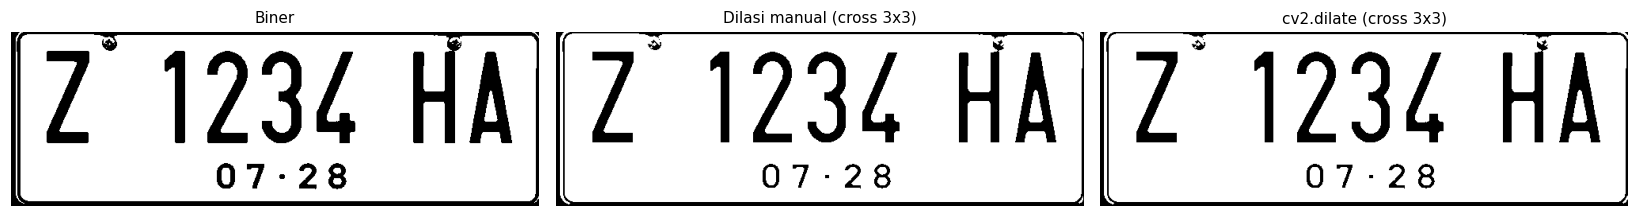

In [22]:
se_cross3 = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
print("SE cross 3x3 dari OpenCV:\n", se_cross3)

dilasi_lib = cv2.dilate(thresh, se_cross3, iterations=1)
dilasi_manual_cross = dilasi_cepat(thresh, se_cross3)

selisih = int(np.count_nonzero(dilasi_lib != dilasi_manual_cross))
print("piksel berbeda:", selisih, f"({selisih / thresh.size:.3%} dari total piksel)")

tampilkan(
    [thresh, dilasi_manual_cross, dilasi_lib],
    ["Biner", "Dilasi manual (cross 3x3)", "cv2.dilate (cross 3x3)"],
    ncols=3, skala=5,
)

## D.3 Erosi manual (square, rectangle, line)


In [23]:
def erosi_modul_literal(F, se):
    """Kode erosi persis seperti modul (mengandung bug untuk SE bercelah)."""
    m, n = F.shape
    kh, kw = se.shape
    a, b = kh // 2, kw // 2

    hasil = np.zeros((m, n), dtype=np.uint8)
    for i in range(a, m - a):
        for j in range(b, n - b):
            temp = F[i - a:i + a + 1, j - b:j + b + 1]
            hasil[i, j] = np.min(temp * se)
    return hasil


def erosi_manual(F, se):
    """Erosi yang benar: hanya piksel di bawah elemen SE = 1 yang diperiksa."""
    m, n = F.shape
    kh, kw = se.shape
    a, b = kh // 2, kw // 2

    hasil = np.zeros((m, n), dtype=np.uint8)
    for i in range(a, m - a):
        for j in range(b, n - b):
            temp = F[i - a:i + a + 1, j - b:j + b + 1]
            nilai = temp[se > 0]
            hasil[i, j] = np.min(nilai) if nilai.size else 0
    return hasil


def erosi_cepat(F, se):
    """Erosi vectorized: loop hanya pada elemen SE yang bernilai 1."""
    m, n = F.shape
    kh, kw = se.shape
    a, b = kh // 2, kw // 2

    pad = np.pad(F, ((a, kh - 1 - a), (b, kw - 1 - b)), mode="constant", constant_values=255)
    hasil = np.full((m, n), 255, dtype=np.uint8)
    for u in range(kh):
        for v in range(kw):
            if se[u, v]:
                hasil = np.minimum(hasil, pad[u:u + m, v:v + n])

    hasil[:a, :] = 0
    hasil[m - a:, :] = 0
    hasil[:, :b] = 0
    hasil[:, n - b:] = 0
    return hasil

putih sebelum erosi : 115951
putih erosi (bug)   : 0
putih erosi (benar) : 110410
manual == vectorized: True


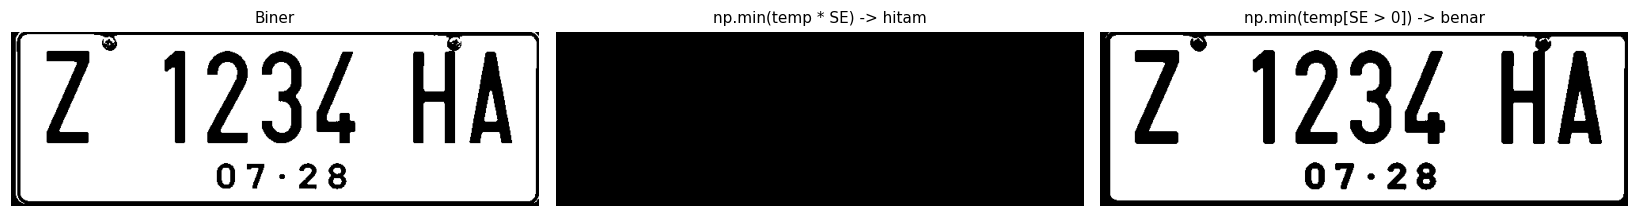

In [24]:
se_cross3 = se_cross(3)

erosi_bug = erosi_modul_literal(thresh, se_cross3)
erosi_benar = erosi_cepat(thresh, se_cross3)

print("putih sebelum erosi :", cv2.countNonZero(thresh))
print("putih erosi (bug)   :", cv2.countNonZero(erosi_bug))
print("putih erosi (benar) :", cv2.countNonZero(erosi_benar))
print("manual == vectorized:", np.array_equal(erosi_manual(thresh, se_cross3), erosi_benar))

tampilkan(
    [thresh, erosi_bug, erosi_benar],
    ["Biner", "np.min(temp * SE) -> hitam", "np.min(temp[SE > 0]) -> benar"],
    ncols=3, skala=5,
)

plat nomer.jpg       <- ./plat nomer.png                                   shape=(220, 667)
SE persegi 5x5 | putih 110344 -> 98443


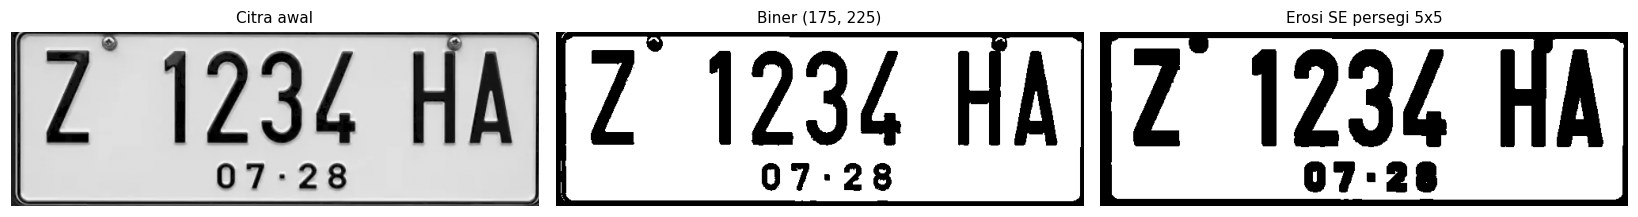

In [25]:
img_e = muat("plat nomer.jpg", PENGGANTI["plat nomer.jpg"])
_, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)

k = 5
imgE = erosi_cepat(thresh1, se_persegi(k))
print(f"SE persegi {k}x{k} | putih {cv2.countNonZero(thresh1)} -> {cv2.countNonZero(imgE)}")

tampilkan(
    [img_e, thresh1, imgE],
    ["Citra awal", "Biner (175, 225)", f"Erosi SE persegi {k}x{k}"],
    ncols=3, skala=5,
)

SE rectangle 3x5 (baris x kolom) | putih -> 101319


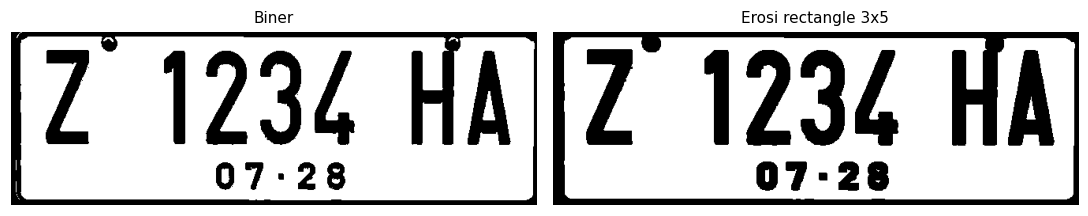

SE rectangle 5x7 (baris x kolom) | putih -> 95473


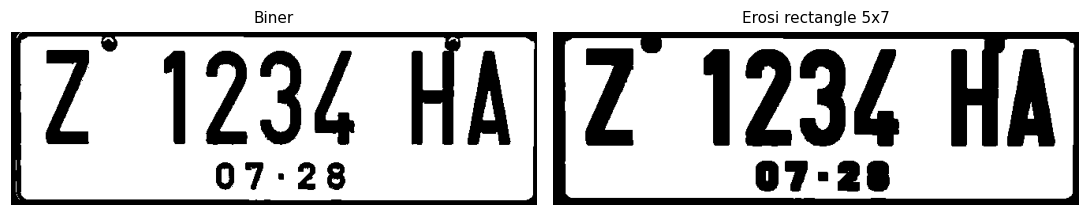

In [26]:
# Rectangle: (tinggi, lebar) pada array NumPy
for tinggi, lebar in [(3, 5), (5, 7)]:
    se_rect = se_persegi_panjang(tinggi, lebar)
    hasil = erosi_cepat(thresh1, se_rect)
    print(f"SE rectangle {tinggi}x{lebar} (baris x kolom) | putih -> {cv2.countNonZero(hasil)}")
    tampilkan(
        [thresh1, hasil],
        ["Biner", f"Erosi rectangle {tinggi}x{lebar}"],
        ncols=2, skala=5,
    )

j.png                <- ./j.jpeg                                           shape=(150, 112)
SE garis vertikal 3 (shape (3, 1)) | putih -> 2175


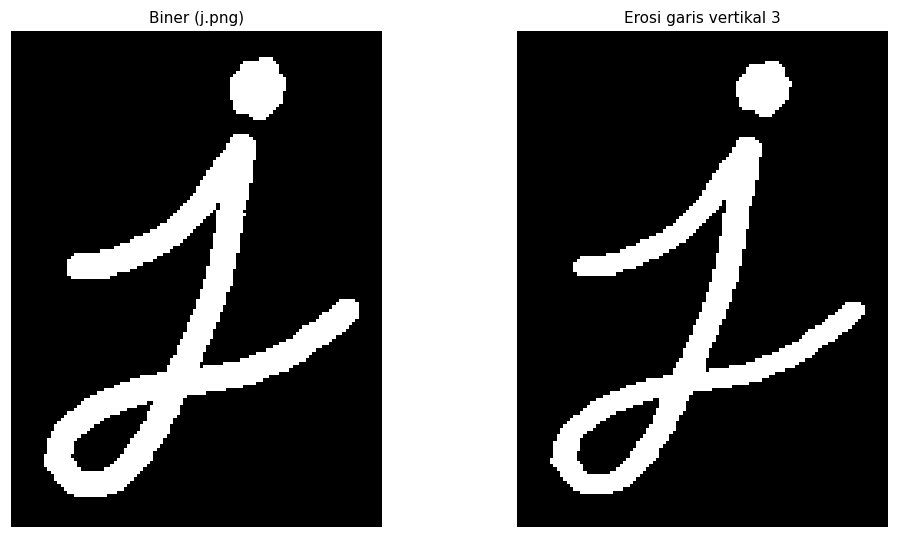

SE garis vertikal 5 (shape (5, 1)) | putih -> 1775


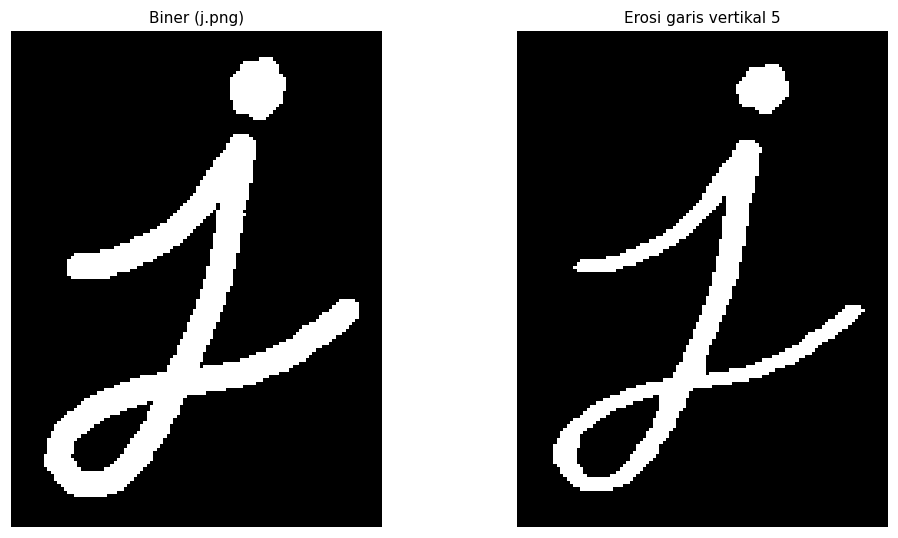

In [27]:
img_j = muat("j.png", PENGGANTI["j.png"])
_, thresh_j = cv2.threshold(img_j, 127, 225, cv2.THRESH_BINARY)

for k in (3, 5):
    se_line = se_garis_vertikal(k)
    hasil = erosi_cepat(thresh_j, se_line)
    print(f"SE garis vertikal {k} (shape {se_line.shape}) | putih -> {cv2.countNonZero(hasil)}")
    tampilkan(
        [thresh_j, hasil],
        ["Biner (j.png)", f"Erosi garis vertikal {k}"],
        ncols=2, skala=5,
    )

## D.4 Erosi dengan library OpenCV


RECT 
 [[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]] 

CROSS 
 [[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]] 

ELLIPSE 
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]] 



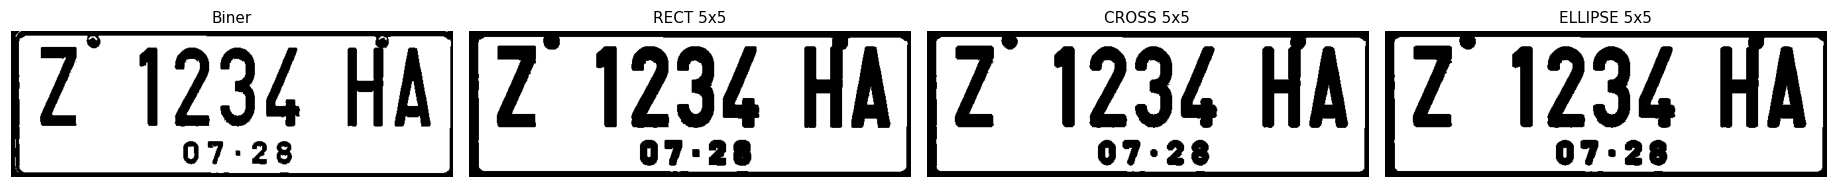

In [28]:
se_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
se_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5))
se_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

for nama, se in [("RECT", se_rect), ("CROSS", se_cross), ("ELLIPSE", se_ellipse)]:
    print(nama, "\n", se, "\n")

erosi_lib = {
    "RECT 5x5": cv2.erode(thresh1, se_rect, iterations=1),
    "CROSS 5x5": cv2.erode(thresh1, se_cross, iterations=1),
    "ELLIPSE 5x5": cv2.erode(thresh1, se_ellipse, iterations=1),
}

tampilkan(
    [thresh1] + list(erosi_lib.values()),
    ["Biner"] + list(erosi_lib.keys()),
    ncols=4, skala=4.2,
)

## D.5 Opening dan Closing


putih sebelum opening : 110948
putih setelah opening : 110152
selisih manual vs lib : 0
idempotent            : True


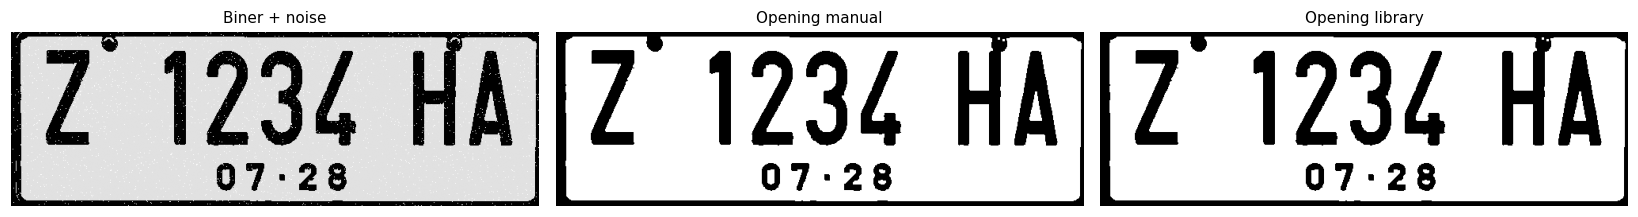

In [29]:
def opening_manual(F, se):
    return dilasi_cepat(erosi_cepat(F, se), se)


def closing_manual(F, se):
    return erosi_cepat(dilasi_cepat(F, se), se)


se3 = se_persegi(3)

bising = thresh1.copy()
rng = np.random.default_rng(42)
titik = rng.integers(0, [bising.shape[0], bising.shape[1]], size=(2500, 2))
bising[titik[:, 0], titik[:, 1]] = 255

open_manual = opening_manual(bising, se3)
open_lib = cv2.morphologyEx(bising, cv2.MORPH_OPEN, se3)
open_lib_ulang = cv2.morphologyEx(open_lib, cv2.MORPH_OPEN, se3)

print("putih sebelum opening :", cv2.countNonZero(bising))
print("putih setelah opening :", cv2.countNonZero(open_lib))
print("selisih manual vs lib :", int(np.count_nonzero(open_manual != open_lib)))
print("idempotent            :", np.array_equal(open_lib, open_lib_ulang))

tampilkan(
    [bising, open_manual, open_lib],
    ["Biner + noise", "Opening manual", "Opening library"],
    ncols=3, skala=5,
)

selisih manual vs lib : 0
putih sebelum/sesudah : 5683 -> 5695


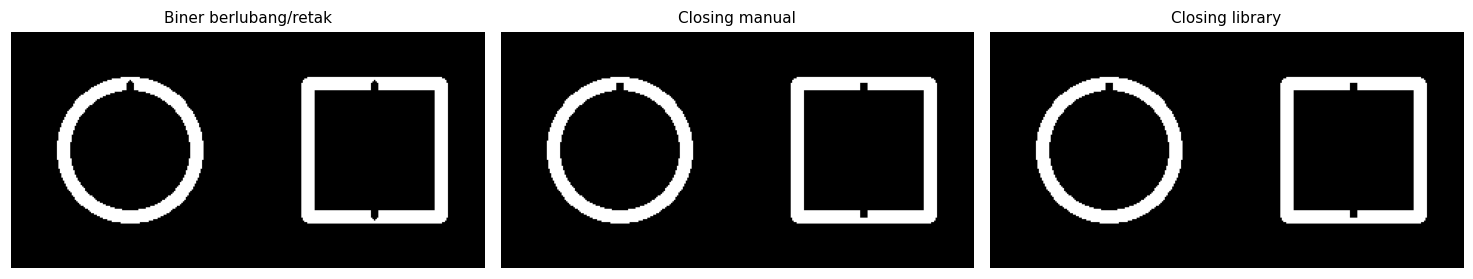

In [30]:
kanvas = np.zeros((160, 320), dtype=np.uint8)
cv2.circle(kanvas, (80, 80), 45, 255, 8)
cv2.line(kanvas, (80, 35), (80, 55), 0, 3)
cv2.rectangle(kanvas, (200, 35), (290, 125), 255, 8)
cv2.line(kanvas, (245, 35), (245, 125), 0, 3)

se5 = se_persegi(5)
tutup_manual = closing_manual(kanvas, se5)
tutup_lib = cv2.morphologyEx(kanvas, cv2.MORPH_CLOSE, se5)

print("selisih manual vs lib :", int(np.count_nonzero(tutup_manual != tutup_lib)))
print("putih sebelum/sesudah :", cv2.countNonZero(kanvas), "->", cv2.countNonZero(tutup_lib))

tampilkan(
    [kanvas, tutup_manual, tutup_lib],
    ["Biner berlubang/retak", "Closing manual", "Closing library"],
    ncols=3, skala=4.5,
)

## D.6 Top-hat dan Black-hat (bottom-hat)


kitten01.jpg         <- ./kitten01.jpeg                                    shape=(561, 600)
top-hat  = img - opening : True
black-hat = closing - img: True


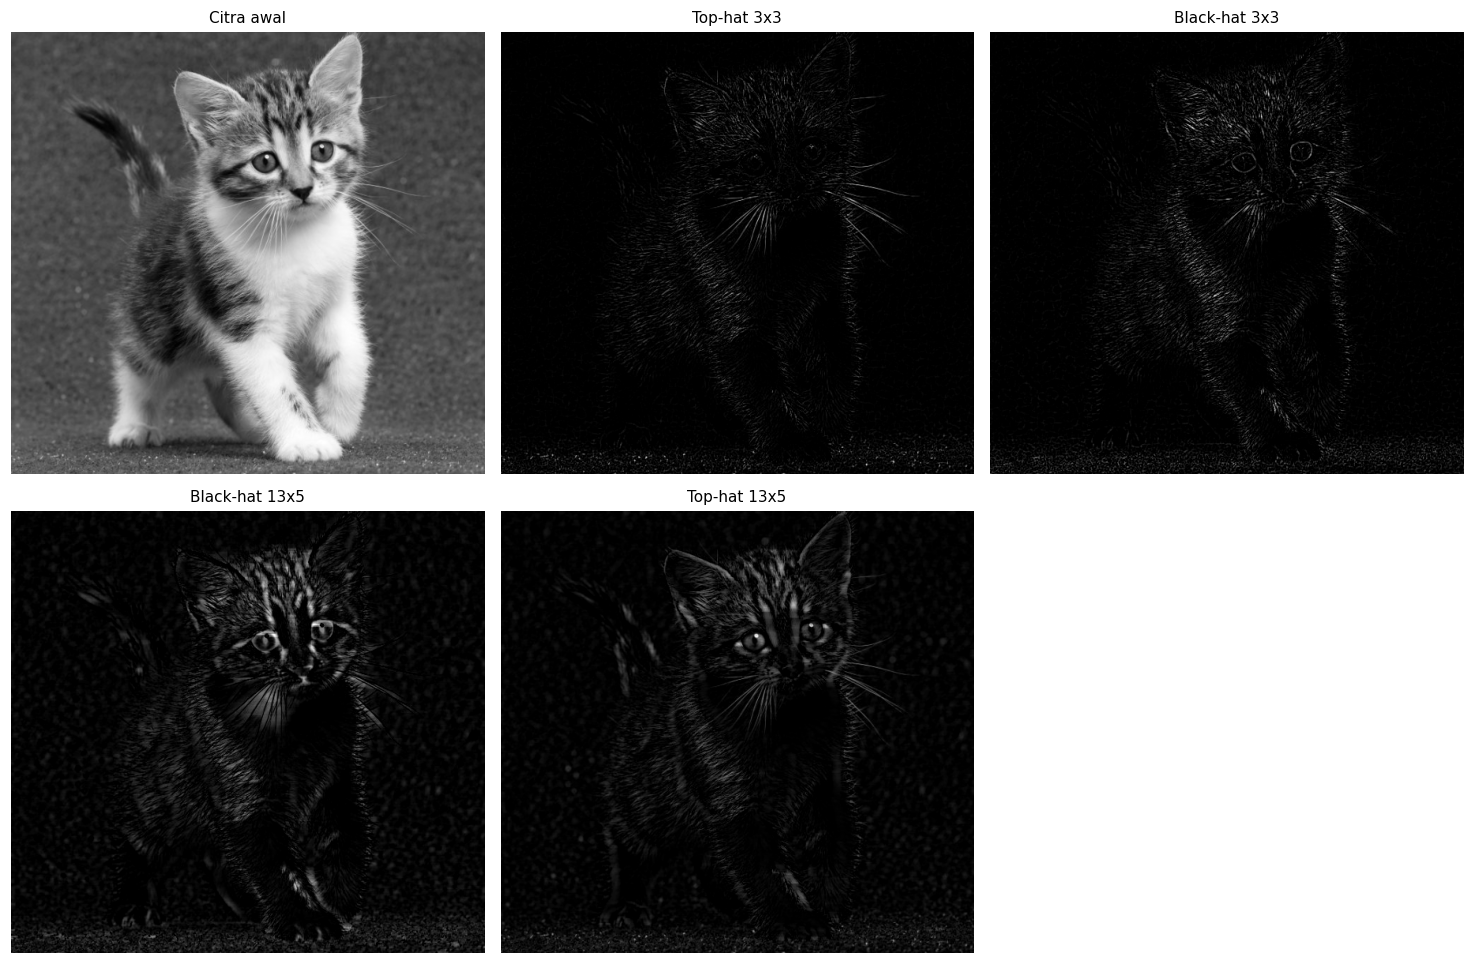

In [31]:
img_kitten = muat("kitten01.jpg", PENGGANTI["kitten01.jpg"], lebar_maks=600)

kernel3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
tophat = cv2.morphologyEx(img_kitten, cv2.MORPH_TOPHAT, kernel3)
blackhat = cv2.morphologyEx(img_kitten, cv2.MORPH_BLACKHAT, kernel3)

tophat_manual = cv2.subtract(img_kitten, cv2.morphologyEx(img_kitten, cv2.MORPH_OPEN, kernel3))
blackhat_manual = cv2.subtract(cv2.morphologyEx(img_kitten, cv2.MORPH_CLOSE, kernel3), img_kitten)

print("top-hat  = img - opening :", np.array_equal(tophat, tophat_manual))
print("black-hat = closing - img:", np.array_equal(blackhat, blackhat_manual))

kernel_panjang = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat_panjang = cv2.morphologyEx(img_kitten, cv2.MORPH_BLACKHAT, kernel_panjang)
tophat_panjang = cv2.morphologyEx(img_kitten, cv2.MORPH_TOPHAT, kernel_panjang)

tampilkan(
    [img_kitten, tophat, blackhat, blackhat_panjang, tophat_panjang],
    ["Citra awal", "Top-hat 3x3", "Black-hat 3x3", "Black-hat 13x5", "Top-hat 13x5"],
    ncols=3, skala=4.5,
)

## D.7 Skeleton

lily.jpg             <- ./lily.jpeg                                        shape=(577, 600)
threshold_triangle : 253.0
piksel objek (V)   : 194888
panjang skeleton   : 11060
intensitas I = l/V : 0.0568


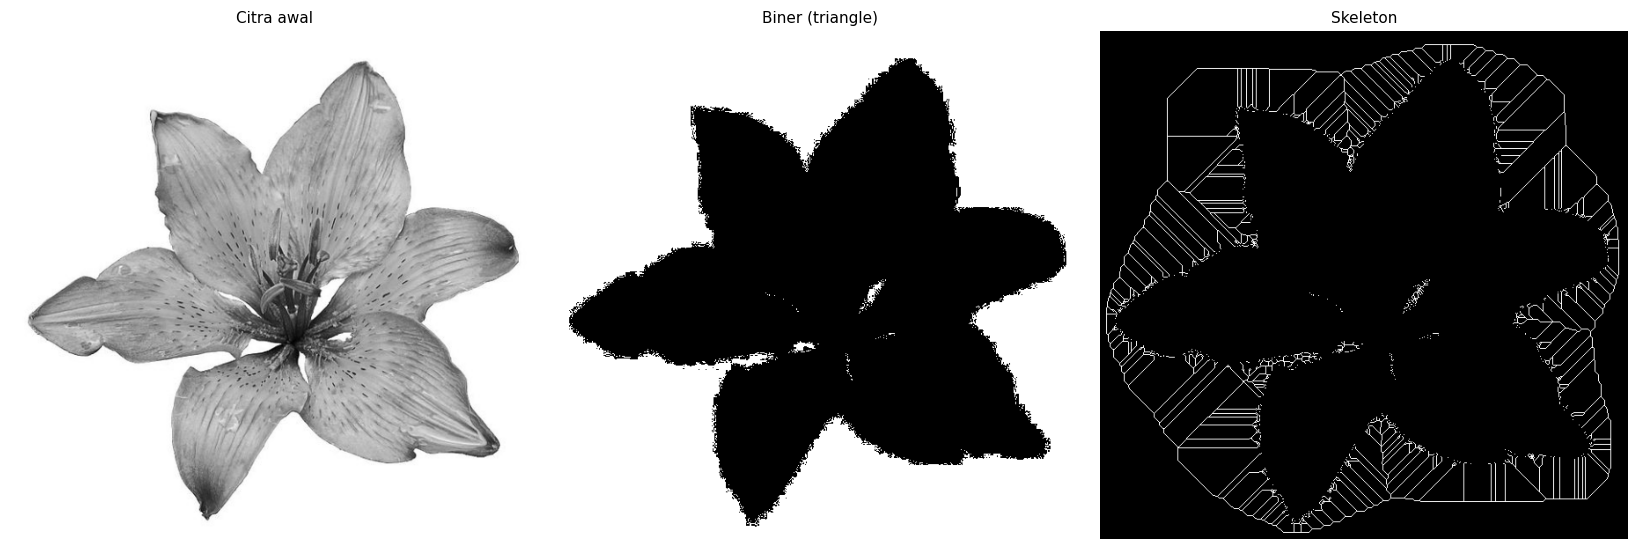

In [32]:
img_lily = muat("lily.jpg", PENGGANTI["lily.jpg"], lebar_maks=600)

ambang = filters.threshold_triangle(img_lily)
biner = img_lily > ambang
skel = skeletonize(biner)

panjang = int(np.count_nonzero(skel))
volume = int(np.count_nonzero(biner))
intensitas = panjang / volume if volume else 0

print(f"threshold_triangle : {ambang:.1f}")
print(f"piksel objek (V)   : {volume}")
print(f"panjang skeleton   : {panjang}")
print(f"intensitas I = l/V : {intensitas:.4f}")

tampilkan(
    [img_lily, biner, skel],
    ["Citra awal", "Biner (triangle)", "Skeleton"],
    ncols=3, skala=5,
)

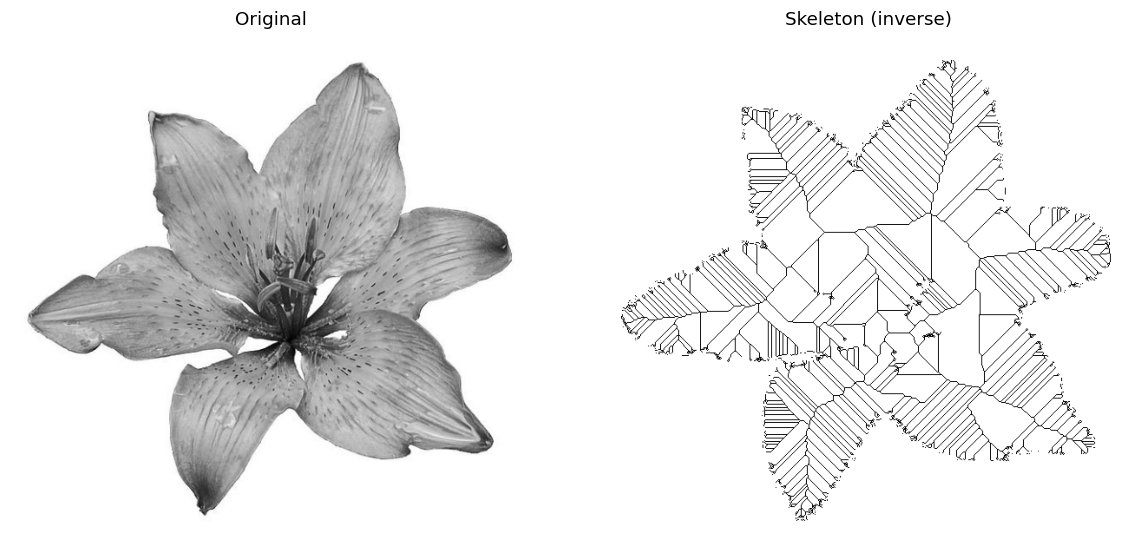

panjang skeleton inverse: 14119


In [34]:
biner_inv = img_lily < ambang
skel_inv = skeletonize(biner_inv)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(img_lily, cmap="gray")
ax[0].set_title("Original")
ax[0].axis("off")
ax[1].imshow(skel_inv, cmap="gray_r")
ax[1].set_title("Skeleton (inverse)")
ax[1].axis("off")
plt.tight_layout()
plt.show()

print("panjang skeleton inverse:", int(np.count_nonzero(skel_inv)))

## D.8 Thinning dan Thickening


pola uji (1 = objek):
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 1 1 1 1 1 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

hasil hit-or-miss (1 = pola cross ditemukan):
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]

piksel objek         : 22123
piksel thin          : 6606
piksel thick (kompl) : 324191


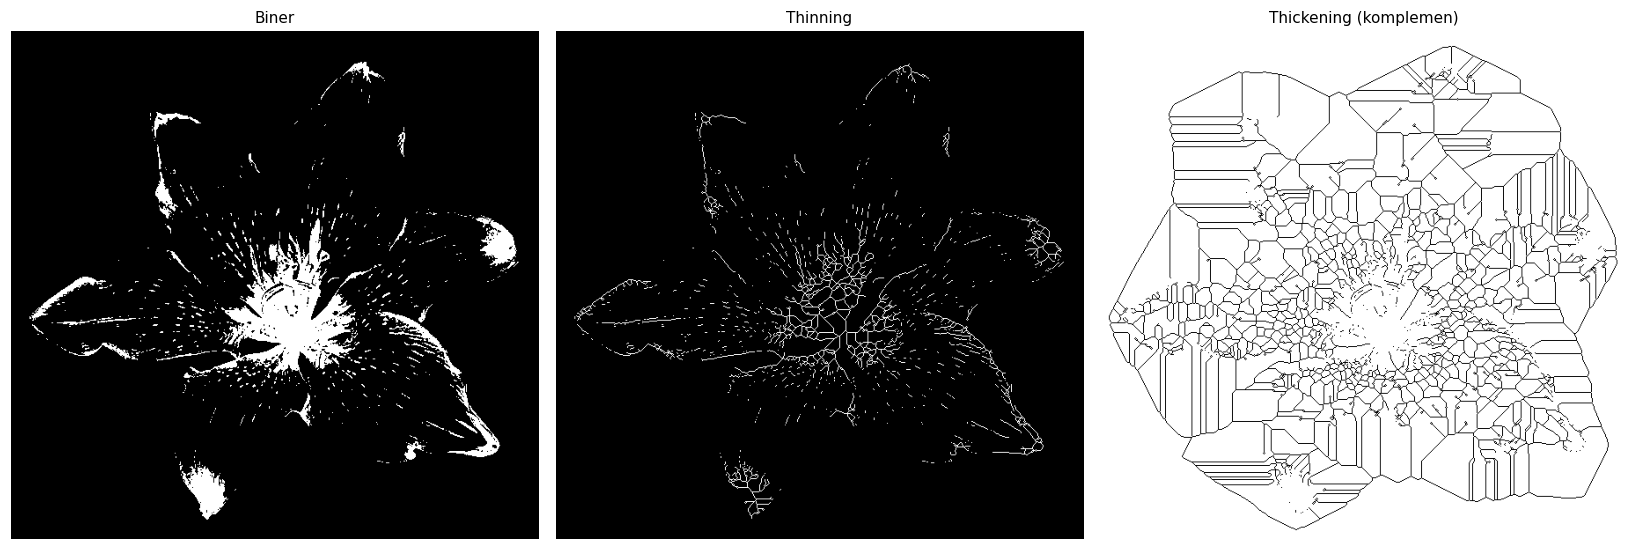

In [33]:
def hit_or_miss_manual(citra, pola_depan, pola_belakang=None):
    """A ⊛ B = (A erosi B1) ∩ (A komplemen erosi B2).

    B1 = pola yang harus terpenuhi (foreground), B2 = pola latar.
    Jika B2 tidak diberikan, dipakai komplemen B1.
    """
    A = (citra > 0).astype(np.uint8) * 255
    B1 = (np.asarray(pola_depan) > 0).astype(np.uint8)
    B2 = 1 - B1 if pola_belakang is None else (np.asarray(pola_belakang) > 0).astype(np.uint8)

    cocok_depan = erosi_cepat(A, B1)
    cocok_belakang = erosi_cepat(cv2.bitwise_not(A), B2)
    return cv2.bitwise_and(cocok_depan, cocok_belakang)


def thickening_manual(citra, pola_depan, pola_belakang=None, iterasi=1):
    """A = A ∪ (A ⊛ B), diulang beberapa kali."""
    A = (citra > 0).astype(np.uint8) * 255
    for _ in range(iterasi):
        A = cv2.bitwise_or(A, hit_or_miss_manual(A, pola_depan, pola_belakang))
    return A


biner_lily = img_lily < 128
tipis = thin(biner_lily)
tebal_komplemen = ~thin(~biner_lily)

pola_cross = np.array([[0, 1, 0],
                       [1, 1, 1],
                       [0, 1, 0]], dtype=np.uint8)

pola_uji = np.zeros((9, 9), dtype=np.uint8)
pola_uji[2:7, 4] = 255
pola_uji[4, 2:7] = 255
hit_uji = hit_or_miss_manual(pola_uji, pola_cross)

print("pola uji (1 = objek):")
print((pola_uji > 0).astype(int))
print("\nhasil hit-or-miss (1 = pola cross ditemukan):")
print((hit_uji > 0).astype(int))

print("\npiksel objek         :", int(biner_lily.sum()))
print("piksel thin          :", int(tipis.sum()))
print("piksel thick (kompl) :", int(tebal_komplemen.sum()))

tampilkan(
    [biner_lily, tipis, tebal_komplemen],
    ["Biner", "Thinning", "Thickening (komplemen)"],
    ncols=3, skala=5,
)

---

# E. Tugas Praktikum — Perbaikan Citra KTP


In [35]:
if IN_COLAB:
    try:
        subprocess.run(["apt-get", "-qq", "install", "-y", "tesseract-ocr"], check=False)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytesseract"], check=False)
    except Exception as e:
        print("Instalasi OCR gagal:", e)

try:
    import pytesseract
    print("Tesseract:", pytesseract.get_tesseract_version())
    OCR_TERSEDIA = True
except Exception as e:
    OCR_TERSEDIA = False
    print("OCR tidak tersedia, evaluasi teks dilewati:", e)

Tesseract: 5.3.4


ktp1_fulan.jpg       <- ktp1_fulan.jpg                                     shape=(458, 694, 3)
ktp2_fulani.jpg      <- ktp2_fulani.jpg                                    shape=(400, 634, 3)

=== KTP 1 (fulan) === shape=(458, 694)
putih biner kartu    : 287799
putih teks (invert)  : 30053
putih opening        : 20108
putih closing        : 33237
putih opening+closing: 20944


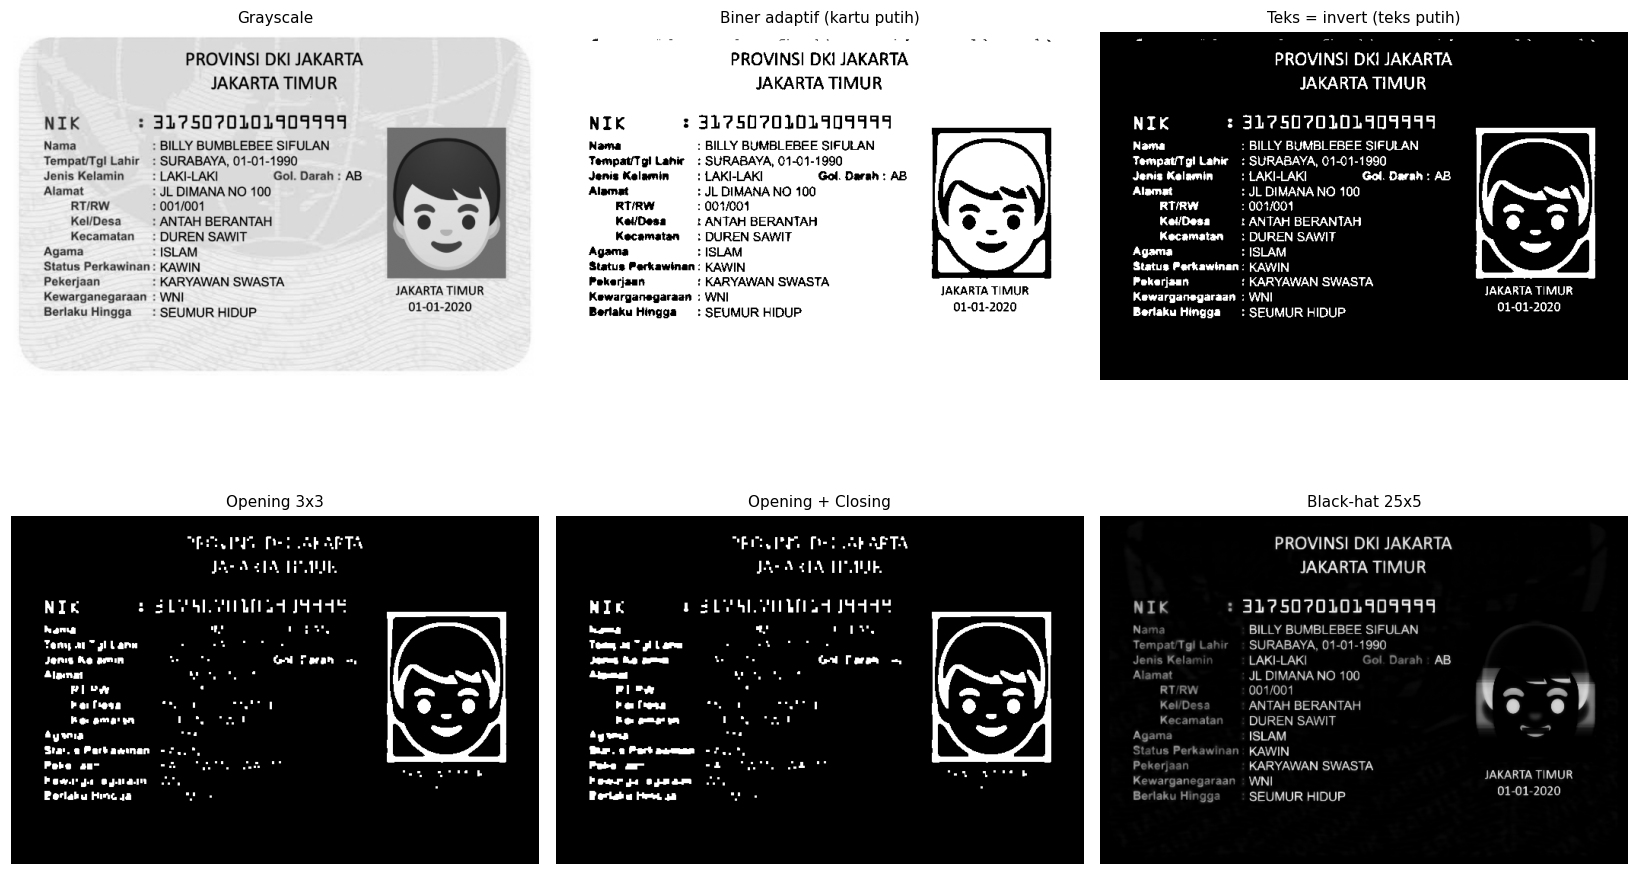


=== KTP 2 (fulani) === shape=(400, 634)
putih biner kartu    : 218641
putih teks (invert)  : 34959
putih opening        : 28604
putih closing        : 37628
putih opening+closing: 29933


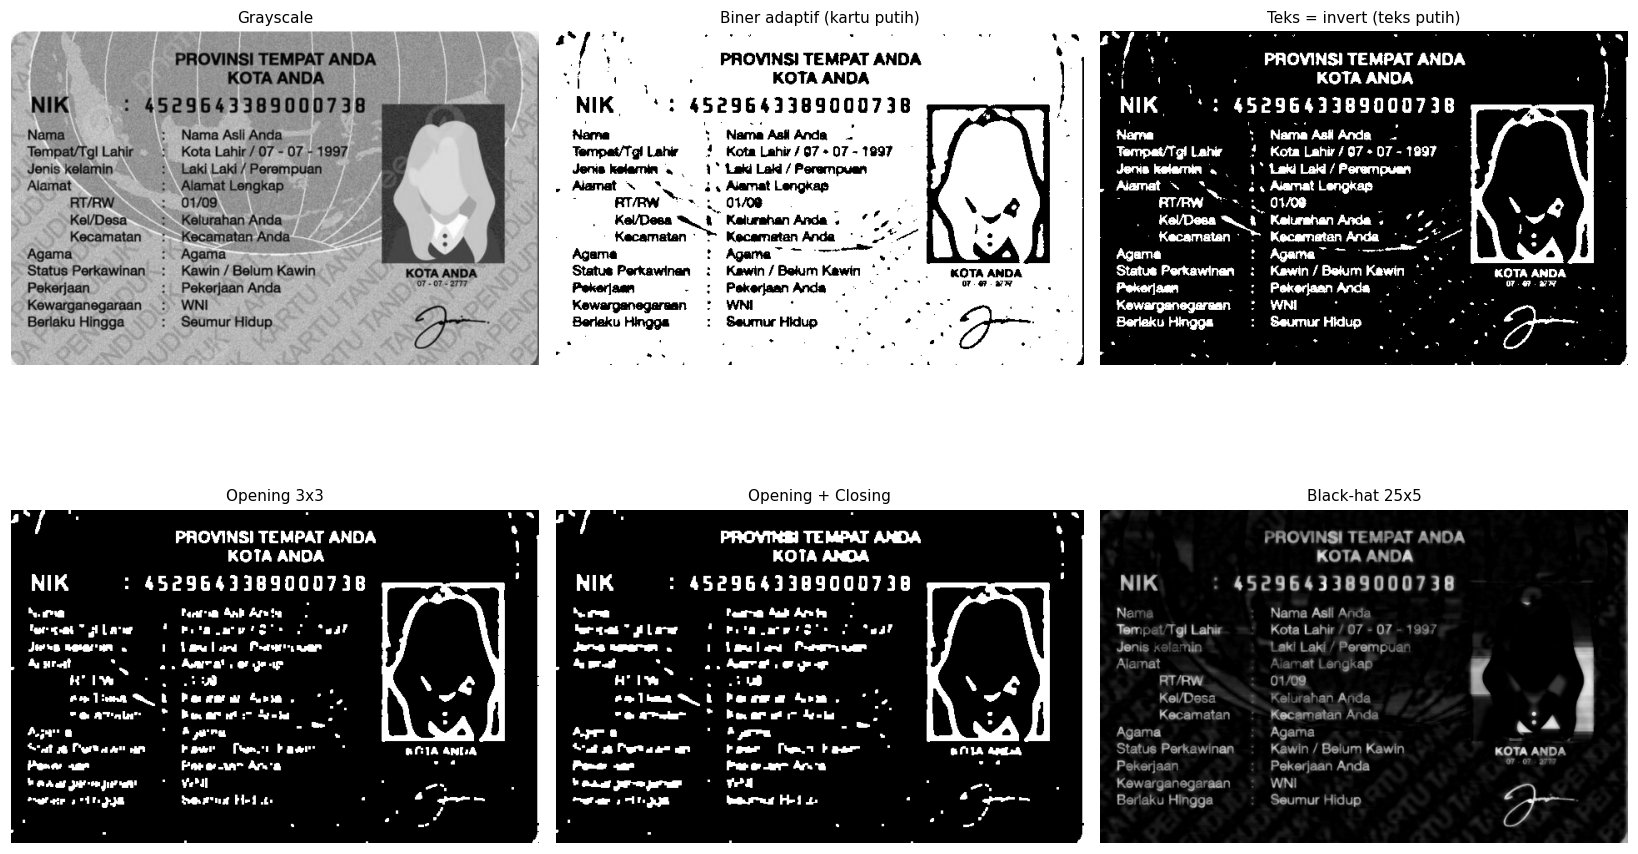

In [36]:
ktp = {
    "KTP 1 (fulan)": muat("ktp1_fulan.jpg", lebar_maks=900, warna=True),
    "KTP 2 (fulani)": muat("ktp2_fulani.jpg", lebar_maks=900, warna=True),
}


def praproses_ktp(img_bgr, lebar_maks=900):
    abu = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    if abu.shape[1] > lebar_maks:
        skala = lebar_maks / abu.shape[1]
        abu = cv2.resize(abu, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)
    halus = cv2.bilateralFilter(abu, 9, 75, 75)
    return abu, halus


def pipeline_ktp(halus, ukuran=3, blok=31, c=10):
    """Binarisasi adaptif lalu balik polaritas agar teks menjadi foreground (putih)."""
    biner = binarisasi(halus, "adaptif", blok=blok, c=c)
    teks = cv2.bitwise_not(biner)
    se = cv2.getStructuringElement(cv2.MORPH_RECT, (ukuran, ukuran))
    buka = cv2.morphologyEx(teks, cv2.MORPH_OPEN, se)
    tutup = cv2.morphologyEx(teks, cv2.MORPH_CLOSE, se)
    gabung = cv2.morphologyEx(buka, cv2.MORPH_CLOSE, se)
    return biner, teks, buka, tutup, gabung


def teks_blackhat(halus, lebar=25, tinggi=5):
    se = cv2.getStructuringElement(cv2.MORPH_RECT, (lebar, tinggi))
    bh = cv2.morphologyEx(halus, cv2.MORPH_BLACKHAT, se)
    _, biner_bh = cv2.threshold(bh, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return bh, biner_bh


hasil_ktp = {}
for nama, img_bgr in ktp.items():
    abu, halus = praproses_ktp(img_bgr)
    biner, teks, buka, tutup, gabung = pipeline_ktp(halus)
    bh, biner_bh = teks_blackhat(halus)

    hasil_ktp[nama] = {
        "bgr": img_bgr,
        "abu": abu,
        "halus": halus,
        "biner": biner,
        "teks": teks,
        "buka": buka,
        "tutup": tutup,
        "gabung": gabung,
        "bh": bh,
        "biner_bh": biner_bh,
    }

    print(f"\n=== {nama} === shape={abu.shape}")
    print("putih biner kartu    :", cv2.countNonZero(biner))
    print("putih teks (invert)  :", cv2.countNonZero(teks))
    print("putih opening        :", cv2.countNonZero(buka))
    print("putih closing        :", cv2.countNonZero(tutup))
    print("putih opening+closing:", cv2.countNonZero(gabung))

    tampilkan(
        [abu, biner, teks, buka, gabung, bh],
        [
            "Grayscale",
            "Biner adaptif (kartu putih)",
            "Teks = invert (teks putih)",
            "Opening 3x3",
            "Opening + Closing",
            "Black-hat 25x5",
        ],
        ncols=3, skala=5,
    )

### E.1 Pengaruh ukuran SE pada opening

Ukuran SE menentukan besar noise yang dihilangkan. Berikut perbandingan opening 3x3, 5x5, dan 7x7 pada KTP pertama.

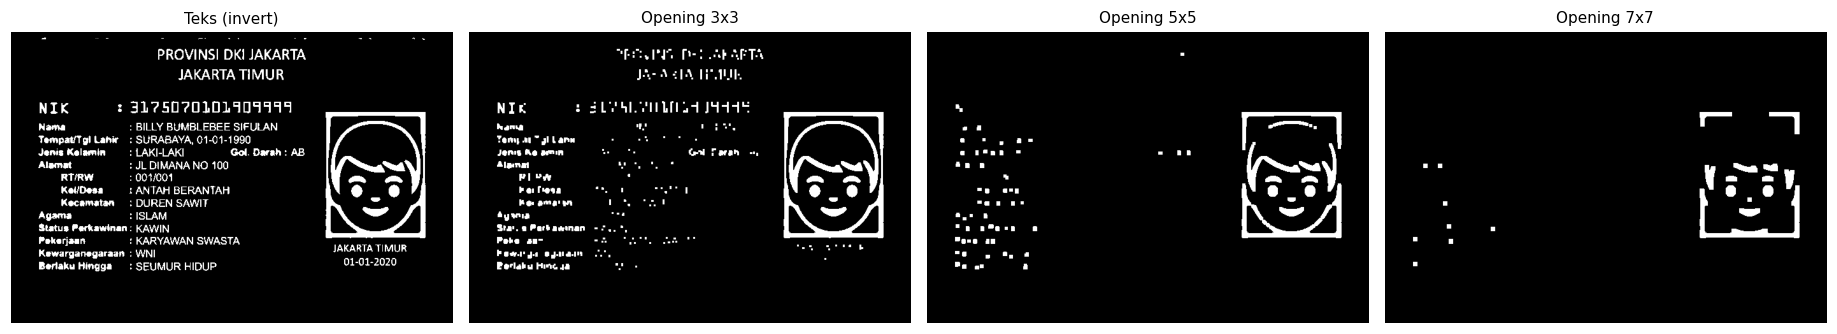

SE 3x3: putih= 20108 | komponen=  326
SE 5x5: putih= 12036 | komponen=   75
SE 7x7: putih=  6684 | komponen=   21


In [37]:
nama_uji = list(ktp)[0]
_, halus_uji = praproses_ktp(ktp[nama_uji])
teks_uji = cv2.bitwise_not(binarisasi(halus_uji, "adaptif", blok=31, c=10))

variasi_buka = [
    cv2.morphologyEx(teks_uji, cv2.MORPH_OPEN, se_persegi(k))
    for k in (3, 5, 7)
]

tampilkan(
    [teks_uji] + variasi_buka,
    ["Teks (invert)", "Opening 3x3", "Opening 5x5", "Opening 7x7"],
    ncols=4, skala=4.2,
)

for k, citra in zip((3, 5, 7), variasi_buka):
    jumlah, _ = cv2.connectedComponents(citra)
    print(f"SE {k}x{k}: putih={cv2.countNonZero(citra):6d} | komponen={jumlah - 1:5d}")

### E.2 Evaluasi OCR sebelum vs sesudah morfologi

Setiap varian citra dibaca dengan `pytesseract` (`--psm 6`, satu blok teks seragam).
Metrik yang dibandingkan:

- **karakter** — jumlah karakter teks yang berhasil dibaca,
- **NIK** — ada/tidaknya 16 digit angka yang terdeteksi,
- **confidence** — rata-rata nilai keyakinan OCR (0–100).

Jika Tesseract tidak tersedia (misalnya saat dijalankan lokal tanpa binary Tesseract), tabel tetap ditampilkan dengan nilai kosong.

In [38]:
def cetak_tabel(baris, kolom):
    """Cetak tabel teks sederhana tanpa dependensi pandas."""
    lebar = {}
    for k in kolom:
        nilai = [len(str(b.get(k, ""))) for b in baris] or [0]
        lebar[k] = max(len(k), *nilai)
    print("  ".join(k.ljust(lebar[k]) for k in kolom))
    print("  ".join("-" * lebar[k] for k in kolom))
    for b in baris:
        print("  ".join(str(b.get(k, "")).ljust(lebar[k]) for k in kolom))


def baca_teks(img, psm=6):
    if not OCR_TERSEDIA:
        return {"karakter": 0, "nik": "", "confidence": np.nan, "cuplikan": ""}

    data = pytesseract.image_to_data(
        img, config=f"--psm {psm}", output_type=pytesseract.Output.DICT
    )
    kata = [t.strip() for t in data["text"] if t and t.strip()]
    teks = " ".join(kata)

    conf = [
        float(c) for c, t in zip(data["conf"], data["text"])
        if t and t.strip() and float(c) >= 0
    ]
    angka = re.sub(r"\D", "", teks)
    nik = re.findall(r"\d{16}", angka)

    return {
        "karakter": len(teks.replace(" ", "")),
        "nik": ",".join(nik[:2]),
        "confidence": round(float(np.mean(conf)), 2) if conf else np.nan,
        "cuplikan": teks[:60],
    }


baris = []
for nama, hasil in hasil_ktp.items():
    varian = {
        "Grayscale asli": hasil["halus"],
        "Biner Otsu": binarisasi(hasil["halus"], "otsu"),
        "Biner adaptif": hasil["biner"],
        "Opening + Closing": cv2.bitwise_not(hasil["gabung"]),
        "Black-hat (invert)": cv2.bitwise_not(hasil["biner_bh"]),
    }
    for label, citra in varian.items():
        info = baca_teks(citra)
        baris.append({"KTP": nama, "Varian": label, **info})

cetak_tabel(baris, ["KTP", "Varian", "karakter", "nik", "confidence"])
print("\nCuplikan teks terbaik per KTP:")
for nama in hasil_ktp:
    kandidat = [b for b in baris if b["KTP"] == nama]
    terbaik = max(kandidat, key=lambda b: (b["karakter"], b["confidence"] if not np.isnan(b["confidence"]) else 0))
    print(f"- {nama}: {terbaik['Varian']} -> {terbaik['cuplikan']!r}")

KTP             Varian              karakter  nik                                confidence
--------------  ------------------  --------  ---------------------------------  ----------
KTP 1 (fulan)   Grayscale asli      333       3175070101909959,9010119901000010  65.86     
KTP 1 (fulan)   Biner Otsu          335       3175070101909959,4901011990100001  65.67     
KTP 1 (fulan)   Biner adaptif       349       3317507010159099,5990101199010020  68.82     
KTP 1 (fulan)   Opening + Closing   180                                          26.23     
KTP 1 (fulan)   Black-hat (invert)  343       3175070101909959,4901011990110090  68.8      
KTP 2 (fulani)  Grayscale asli      329       4529643389000738                   70.73     
KTP 2 (fulani)  Biner Otsu          334       4529643385900073                   53.32     
KTP 2 (fulani)  Biner adaptif       378       7452964373890007,3840707199714401  44.31     
KTP 2 (fulani)  Opening + Closing   252       4529643389000738                  

### E.3 Metrik piksel dan connected components

Opening menurunkan jumlah piksel foreground dan komponen berukuran besar (noise kecil hilang). Jumlah komponen total bisa sedikit berubah karena goresan tipis yang terputus ikut hilang. Closing justru menurunkan jumlah komponen total karena goresan/huruf yang berdekatan menyatu.

In [39]:
baris = []
for nama, hasil in hasil_ktp.items():
    for label, kunci in [
        ("Teks (invert)", "teks"),
        ("Opening", "buka"),
        ("Closing", "tutup"),
        ("Opening + Closing", "gabung"),
    ]:
        citra = hasil[kunci]
        jumlah, _, stat, _ = cv2.connectedComponentsWithStats(citra, connectivity=8)
        luas = stat[1:, cv2.CC_STAT_AREA] if jumlah > 1 else np.array([0])
        baris.append({
            "KTP": nama,
            "Varian": label,
            "Foreground (%)": round(100 * cv2.countNonZero(citra) / citra.size, 2),
            "Komponen": jumlah - 1,
            "Komponen >= 20 px": int(np.sum(luas >= 20)),
        })

cetak_tabel(baris, ["KTP", "Varian", "Foreground (%)", "Komponen", "Komponen >= 20 px"])

KTP             Varian             Foreground (%)  Komponen  Komponen >= 20 px
--------------  -----------------  --------------  --------  -----------------
KTP 1 (fulan)   Teks (invert)      9.46            324       274              
KTP 1 (fulan)   Opening            6.33            326       171              
KTP 1 (fulan)   Closing            10.46           149       110              
KTP 1 (fulan)   Opening + Closing  6.59            225       123              
KTP 2 (fulani)  Teks (invert)      13.79           358       171              
KTP 2 (fulani)  Opening            11.28           344       249              
KTP 2 (fulani)  Closing            14.84           288       123              
KTP 2 (fulani)  Opening + Closing  11.8            226       174              


### E.4 Ekstraksi baris teks dan area NIK

Setelah opening + closing, baris teks disatukan dengan closing horizontal (SE lebar) lalu dideteksi dengan
*connected components*. Kotak terbesar biasanya berisi baris teks utama, dan area NIK dapat dipotong dari situ.


=== KTP 1 (fulan) === 6 baris teks terdeteksi
kotak terbesar (272x19) -> karakter=11 | NIK=-


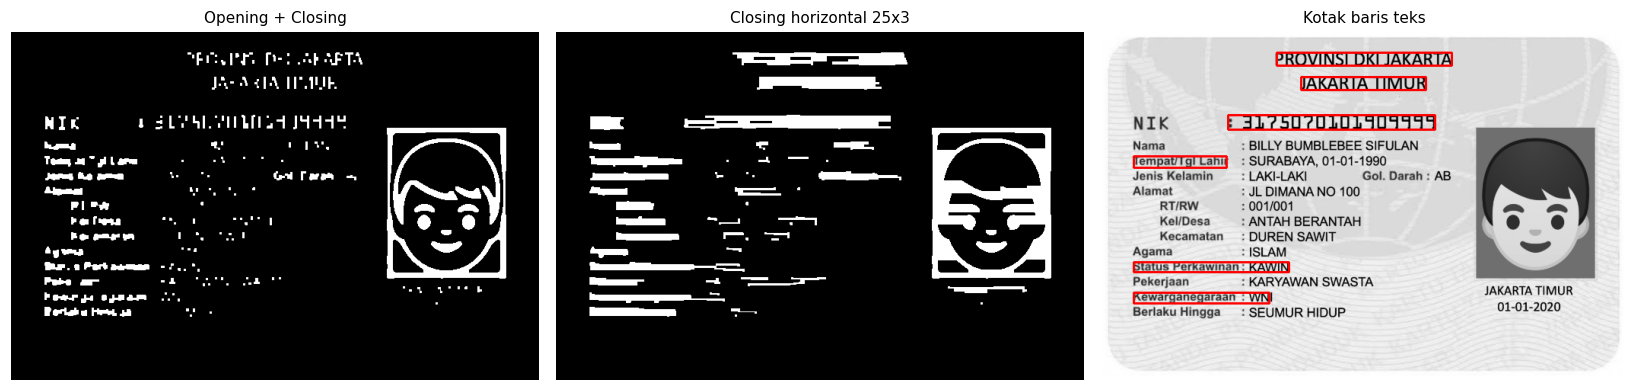


=== KTP 2 (fulani) === 6 baris teks terdeteksi
kotak terbesar (269x16) -> karakter=16 | NIK=-


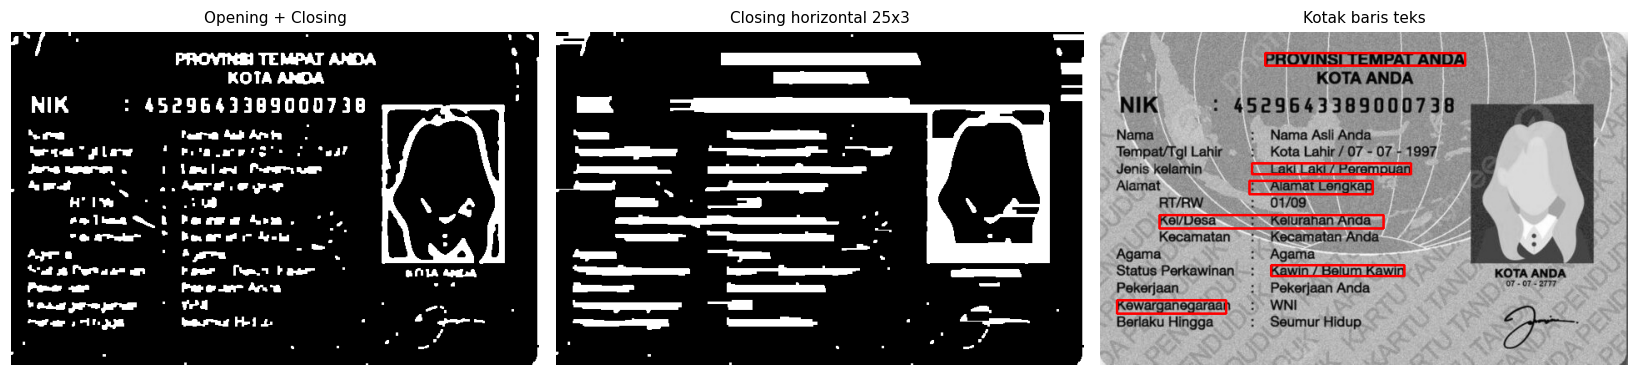

In [40]:
def deteksi_baris_teks(biner, lebar_gabung=25, area_min=1200, maks=6):
    se = cv2.getStructuringElement(cv2.MORPH_RECT, (lebar_gabung, 3))
    gabung = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, se)
    kontur, _ = cv2.findContours(gabung, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    kotak = [cv2.boundingRect(c) for c in kontur]
    kotak = [k for k in kotak if k[2] * k[3] >= area_min and k[2] >= 2.5 * k[3]]
    kotak.sort(key=lambda k: k[2] * k[3], reverse=True)
    return gabung, kotak[:maks]


for nama, hasil in hasil_ktp.items():
    gabung_baris, kotak = deteksi_baris_teks(hasil["gabung"])

    kanvas = cv2.cvtColor(hasil["abu"], cv2.COLOR_GRAY2BGR)
    for x, y, w, h in kotak:
        cv2.rectangle(kanvas, (x, y), (x + w, y + h), (0, 0, 255), 2)

    print(f"\n=== {nama} === {len(kotak)} baris teks terdeteksi")
    if kotak:
        x, y, w, h = kotak[0]
        potong = cv2.bitwise_not(hasil["gabung"][y:y + h, x:x + w])
        info = baca_teks(potong)
        print(f"kotak terbesar ({w}x{h}) -> karakter={info['karakter']} | NIK={info['nik'] or '-'}")

    tampilkan(
        [hasil["gabung"], gabung_baris, cv2.cvtColor(kanvas, cv2.COLOR_BGR2RGB)],
        ["Opening + Closing", "Closing horizontal 25x3", "Kotak baris teks"],
        ncols=3, skala=5,
    )